![AES-CEE Masthead](http://kyrill.ias.sdsmt.edu/wjc/eduresources/AES_CEE_Masthead.png)
# USGS Data Retrieval Demonstration (Single Station Version)

This updates my older R & Python Notebooks that I've used in the past using a similar USGS package that reads from data from the [USGS National Water Information System (NWIS)](https://waterdata.usgs.gov/nwis), but adapted for Python.  This also reflects NWIS's retirement for the [WaterData API](https://api.waterdata.usgs.gov/).

<div class="alert alert-warning" role="alert">
This also shows updates that accommodate the newer USGS API.<b>
The biggest change is the role of the new Key System and the phasing out of the older NWIS system.
</div>

## 1. Objectives

* Be able to read the daily mean streamflow from USGS for a given pre-identified gauge.
* Plot mean daily streamflow
* If needed, export data to an alternative text format (in this case, a comma-delimited (csv) file that MS Excel can read.

## 2. Libraries

This script uses the following libraries

The Basics...

* [numpy](https://numpy.org/): Python's "go-to" library for math and array/matrix structures
* [pandas](https://pandas.pydata.org/): A fast, powerful, flexible and easy to use open source data analysis and manipulation tool that has structures similar to R's "DataFrame"
* [matplotlib](https://matplotlib.org/stable/): Python's "go-to" Graphics Library.
* [seaborn](https://seaborn.pydata.org/): An extention to Pandas that includes resources for statistical graphical data
* [os](https://docs.python.org/3/library/os.html): this is part of the default installation for Python, but must be invoked as if it's an external library.

And more specialized libraries

* [dataretrieval](https://doi-usgs.github.io/dataretrieval-python/): A Python alternative to the USGS R data retrieval package to obtain USGS and EPA water quality data, streamflow data, and metadata directly from their web services portals.

<div class="alert alert-warning" role="alert">
<strong>***DATA LIMITATION WARNING***</strong> Note that the water quality data from EPA is no longer updated</div>

* [pynhd](https://docs.hyriver.io/readme/pynhd.html): part of the HyRiver software stack that is designed to aid in hydroclimate analysis through web services.  This package is provides access to various gepspatial hydromet datasets including the Natuonal Hydrography Dataset (watersheds and steams)

Mapping Resources (When running this as a general Python script, you won't want this part.) You can learn how to use these libraries in the [tutorial making WRF Model Domains](https://wjcapehart.github.io/AES_CEE_Python/Jupyter_Notebooks_and_Other_Files/03_Deep_Dives/03_02_Applications/03_02_05_WRF_and_MPAS_Domain_Mapping/WRF_Map_Out_Namelist_WPS.html).

*  [CartoPy](https://cartopy.readthedocs.io/stable/): A map projection library. We are specifically requesting the following sub-libraries
    *  [CartoPy.crs](https://cartopy.readthedocs.io/stable/reference/crs.html): Cartopy's Coordinate Reference System (CRS) operators. This is the information needed to draw the various projections.
    *  [CartoPy.feature](https://cartopy.readthedocs.io/stable/matplotlib/feature_interface.html): Cartopy's Feature Plotting Interface
    *  [CartoPy.io.img_tiles](https://cartopy.readthedocs.io/stable/reference/io.html): Access to Mapping Tiles
    *  [CartoPy.mpl](https://cartopy.readthedocs.io/stable/reference/matplotlib.html): Cartopy Matplotlib Interface

* [Unidata's MetPy](https://unidata.github.io/MetPy/latest/): Tools for reading, visualizing, and performing calculations with weather data. I'm only using it becasue it has counties and provinces!

* [itables](https://mwouts.github.io/itables/): A Jupyter extension that will allow your tables to be displayed in a manner similar to RStudio, by which you can scroll through them.  If you have big or wide tables, this is what you need to explore your data.  Be aware that you should comment it out if you export your file into a plain *.py executable.
  
<div class="alert alert-danger" role="alert">
<p><strong>***Note for ITables:***</strong> ITables is having difficulties working with [geopandas.GeoPandasDataframes](https://geopandas.org/en/latest/docs/reference/api/geopandas.GeoDataFrame.html), so I have automatically disabled automated ITables features.</p>
<p>
To use ITables on demand you can use the function <a href="https://mwouts.github.io/itables/apps/notebook.html">itables.show()</a></p>
</div>


Non-Library iPython Resource...

* [version_information](https://github.com/jrjohansson/version_information): Package version documentation to aid in replicability. See its use at the bottom of this notebook.

See its use at the bottom of this notebook.  You will need to remove this before saving it as a plain Python "*.py" script.

You may also see me frontload some basic simple functions for common acts in a given script.  Below, you will see such an example with a trick to collapse my multi-index columns into a single row.


<div class="alert alert-danger" role="alert">
<p><strong>***Google Colab Compatability Note:***</strong> This sheet has a section for installing libraries on the Google Colab platform.</p>
<p>
Each time you fire up a Google Colab session you will need to reload any essential libraries.  This is done with the "bang" (!) operator.  The "!" will let you run shell commands within a python code cell.  Below it will be installing a set of non-standard packages that we'll be using here using the pip Python installer package.</a></p>
</div>

In [1]:
##########################################
#
# Uncomment for Google Colab Access Only
#
# !pip install dataretrieval pynhd cartopy itables metpy version_information
#
##########################################

In [2]:
######################################################
#
# Libraries
#

import numpy              as np
import pandas             as pd
import geopandas          as gp
import matplotlib.pyplot  as plt
import seaborn            as sns
import os                 as os
import datetime           as dt

import dataretrieval.nwis      as nwis
import dataretrieval.waterdata as waterdata

import pynhd               as pynhd

add_Pretty_Map = True

import cartopy.crs          as ccrs
import cartopy.feature      as cfeature
import cartopy.io.img_tiles as cimgt
import cartopy.mpl          as cmpl

from metpy.plots            import USCOUNTIES

import itables

from IPython.display import display, HTML


# Set the Indices Display Option to True (it's typically omitted)

itables.options.showIndex = True

# Set the notebook itables model to require active use of itables.show()

itables.init_notebook_mode(all_interactive=False)

#
# Short Functions
#

def flatten_multi_col_index(df):
    '''
    "flattens" the input dataframe's columns from a "multiindex"
    mode to a single row
    '''
    df.columns = ['_'.join(col).strip('_') for col in df.columns.values]
    return df

#
######################################################

## 3. A fast summary of the USGS Water APIs

<div class="alert alert-warning" role="alert">
This is being replaced with the more modern WaterData API.
</div>


The USGS maintains an extensive dataset collection accessible to the public via its web interfaces.  These can be accessed through their "pretty" websites, or by entering a cryptic URL.

However, people who want to forego web clicking and have a programming background may wish to dive directly into the raw data so they can repeatedly pull/analyze it.

The USGS [DataRetrieval](https://doi-usgs.github.io/dataretrieval-python/index.html) package provides resources for accessing multiple USGS data APIs, similar to those developed for NOAA/NWS/NCEI weather and climate data sources.

### 3.1. Map of This Activity

In this exercise, I'll present a typical workflow based on WaterData's predecessor, the NWIS.  

Let's consider a scheme to extract daily stream gage stations data from a given [USGS HUC-08 watershed](https://nas.er.usgs.gov/hucs.aspx).  

My general flow that I'm evolving with this new Water Data API suite is to...

1) Go into a given watershed and find the station location(s) and names.
    1)  This information is carried in the [Monitoring Locations Sub-API](https://api.waterdata.usgs.gov/ogcapi/v0/collections/monitoring-locations)
    2)  When we do this, this will give us a geopandas.GeoDataFrame.
2)  Go back into the same watershed and pull the available stations for your preference and, if needed, start and end times, and specific data types (e.g.).
    1)  This information is kept in a *different* area: [The timeseries metadata Sub-API](https://api.waterdata.usgs.gov/ogcapi/v0/collections/time-series-metadata)
    2)  This is an extra step from the old NWIS days.
    3)  Likewise, this will also come out as a dataframe. You may want to drop the spatial geometry data in this one.
3)  If you had to go through this second step, you can "join" the data using what in Pandas is called a ["merge"](https://pandas.pydata.org/docs/user_guide/merging.html) by matching shared columns in both resulting from these two steps.
4) Now you can fetch your time series data using the
    1) This information is carried in the [Daily Values Sub-API](https://api.waterdata.usgs.gov/ogcapi/v0/collections/daily)
    2) You can do this en masse for the whole basin or pick and choose one station that you really want. (I'll do both.  I recommend the latter!)
5) Then mix, crack, filter, whip, stir, etc your frames into however you need them to be for your specific Scientific Adventure Violence.

As most exercises where I spell out a new procedure with Python or R, I will do this in excruciatingly slow motion, deep diving into each step.

### 3.2 But FIRST!  Get your API Key.

Get your own API key! I have one below.  Use your own. (At some point they will probably revoke mine for breaking the internet.)

Head to the following site:

[https://api.waterdata.usgs.gov/signup/](https://api.waterdata.usgs.gov/signup/)

It will want an email.  Use your official email address.

Once you register, you will get an email delivered from **noreply@api.data.gov**

To source the code, use the following *with your own key*.

<div class="alert alert-danger" role="alert">
The key below is not a real key.  Like, I said, get your own!
</div>
    
This approach will set your "environment variables" with the [os.environment()](https://www.geeksforgeeks.org/python/python-os-environ-object/) command.

Honestly, I am not sure how this works with the new USGS API's python interface.  With NCEI and NASA, these are pushed in as login credentials.  

In [3]:
######################################################
#
# Pulling Station Information
#

usgs_key = "7x1EoAgZJFJb36pG2gPrKQQKsPRIqgsoedR0iqo5"

os.environ["API_USGS_PAT"] = usgs_key

#
######################################################

## 4. Selecting search criteria

I have versions of this script that will pull stations by various search criteria this is a slimmed down one that will only pull a single station.  

### 4.1. Searching by station

For this activity we have a choice of three:

* [USGS-06446500 (White River, near Interioir, SD)](https://waterdata.usgs.gov/monitoring-location/USGS-06446500/#dataTypeId=continuous-00065-0&period=P7D&showFieldMeasurements=true)
* [USGS-04290500 (Winooski River, near Essex Junction, NH)](https://waterdata.usgs.gov/monitoring-location/USGS-04290500/#dataTypeId=continuous-00065-0&period=P7D&showFieldMeasurements=true)
* [USGS-09364010 (Animas River, below Aztec, NM)](https://waterdata.usgs.gov/monitoring-location/USGS-09364010/#dataTypeId=continuous-00065-0&period=P7D&showFieldMeasurements=true)



### 4.2. Other Search Criteria

Here, we may to be more specific and identify the
*  Type of Station or [**site_type_code**](https://api.waterdata.usgs.gov/ogcapi/v0/collections/site-types/items) : For us this will be "ST" or Stream Station.
*  Period of Time Aggregation [**computation_period_identifier**]() : "Daily"
*  Specific Parameter or [**parameter_code**](https://api.waterdata.usgs.gov/ogcapi/v0/collections/parameter-codes/items) : "00060" or Discharge in CFS
*  Statistical Method or [**statistic_id**](https://api.waterdata.usgs.gov/ogcapi/v0/collections/statistic-codes/items) : "00003" or Mean over the period

With this we can make the following request list. (Comment out the stations you don't want to use.)


In [4]:
######################################################
#
# Station Search Criteria
#

site_type_code                = "ST"            # Stream Stations
computation_period_identifier = "Daily"         # Daily Aggregation
parameter_code                = "00060"         # Discharge in cfs
statistic_id                  = "00003"         # Mean

monitoring_location_id        = "USGS-06446500" # "(White River, near Interioir, SD)"
monitoring_location_id        = "USGS-04290500" # "(Winooski River, near Essex Junction, NH)"
monitoring_location_id        = "USGS-09364010" # "(Animas River, below Aztec, NM)"

#
######################################################

### 4.3. Retrieving the Station Location and Specific Data Set Information

The new WaterData's monitoring location data can be pulled with  [dataretrieval.waterdata.get_monitoring_locations](https://doi-usgs.github.io/dataretrieval-python/reference/waterdata.html#dataretrieval.waterdata.get_monitoring_locations)

While there are a LOT of variables to tunnel into for station location information, we're only going to use two: the HUC and the Site type.

The output is two-fold.  You will get a geopandas.GeoDataFrame and a metadata query that can be put into a web browser.

Since this is a GeoDataFrame, you can also do a quick-and-dirty map plot. (We'll make it prettier later.)

Retrieving: monitoring-locations · 1 page · 1 rows · 999/1,000 requests remaining


Monitoring Station Information for USGS-09364010
URL: https://api.waterdata.usgs.gov/ogcapi/v1/collections/monitoring-locations/items?site_type_code=ST&id=USGS-09364010&limit=50000
ANIMAS RIVER BELOW AZTEC, NM


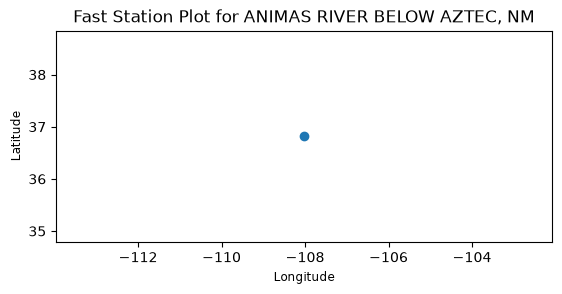

In [5]:
######################################################
#
# Retrieving the Station Location Information
#

df_st_metadata, md_st_metadata =  \
    waterdata.get_monitoring_locations(monitoring_location_id = monitoring_location_id,
                                       site_type_code          = site_type_code)

print("Monitoring Station Information for " + monitoring_location_id )

# Display URL

print("URL:",md_st_metadata.url)

# Display URL Table (you need to drop the geometry column or it will break itables)

# Extract for Labeling Maps the station name

station_names_for_plots = df_st_metadata["monitoring_location_name"].values[0]

print(station_names_for_plots)

itables.show(df      = df_st_metadata.drop(columns=["geometry"]),
             caption = "Monitoring Location for " + station_names_for_plots)

# Fast Station Location Plot

df_st_metadata.plot()
plt.title("Fast Station Plot for "+ station_names_for_plots)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

#
######################################################

Well the above "map" is boring.  (And if you are looking at his in Google Colab the look and feel of the table when rendered in ITables may appear to be drab.).  Put a pin on this we will make a nice map of this shortly!

Also for us to extract the actual time series with the newer USGS water data interface we will need to get a specific catalog identifier to get the specific time series.  This is similar to a "granule" when getting satellite data from NASA.

This will use the [dataretrieval.waterdata.get_time_series_metadata()](https://doi-usgs.github.io/dataretrieval-python/reference/waterdata.html#dataretrieval.waterdata.get_time_series_metadata)

In [6]:
######################################################
#
# Pulling Specific Time Series Catalog Information
#

df_ts_metadata, md_ts_metadata =  \
    waterdata.get_time_series_metadata(monitoring_location_id = monitoring_location_id,
                                       parameter_code         = parameter_code,
                                       statistic_id           = statistic_id)

itables.show(df_ts_metadata)

#
######################################################

Retrieving: time-series-metadata · 1 page · 1 rows · 998/1,000 requests remaining


I find this aspect of the new USGS data services datasets annoying, but I suspect that separating explicit geographic metadata from specific data catalog markers is easier on disk space.

But here it IS a good idea for us to merge our thinned-out dataframe with the spatial information locally.

Of the two dataframes, I checked to see which columns are common to both:

```
print(list(set(df_ts_metadata.columns).intersection(df_st_metadata.columns)))
```
The common values are ['geometry', 'hydrologic_unit_code', 'monitoring_location_id', 'state_name'].

So here I am going to do what in "R" is called a "join" and in Pandas is called a "merge" by columns using [pandas.merge()](https://pandas.pydata.org/docs/reference/api/pandas.merge.html).

In [7]:
######################################################
#
# Trimming down to only currently-active stations
#

df_metadata = pd.merge(left  = df_st_metadata, # The dominant frame (all rows will be retained)
                       right = df_ts_metadata) # The subordinate frame (all rows not in the dom frame will be discarded)

print("Joined Metadata Table")
itables.show(df = df_metadata.drop(columns=["geometry"]))

#
######################################################

Joined Metadata Table




### 4.4 Rabit Hole! Making a Nifty Plot of the Watershed.

Let's do something about the map and add some value: specifically let's take a look at the contributing watershed above the station.  

[PyNHD](https://docs.hyriver.io/readme/pynhd.html) is a part of a larger suite of packages, [HyRiver](https://hyriver.readthedocs.io/en/latest/), that is NOT part of the USGS Python ecosystem (one of the contributors, however, is Ruby Leung at DOE's Pacific Northwest Lab, who is big in the Climate Modeling and Hydrology community).  Warning.  It is a BIG package.  It is currently available under the "base" Python environment on the SD Mines Jupyter Hub Services.

What this will do for you is pull data from the National Hydrography Database form USGS.  This includes polygons of the contributing area for available stream gages and their main stems and tributaries upstream.  (It can also get you the downstream stem if youwant).

To get the contribuing area for a station you can use...

[pynhd.nldi.NLDI.get_basins()](https://docs.hyriver.io/autoapi/pynhd/nldi/index.html#pynhd.nldi.NLDI.get_basins): Access the Hydro Network-Linked Data Index (NLDI) service and extract the basin for a given station ID (note that it works for the USGS-XXXXXXX notation!).

You can also get features like main river stems (up and downstream)
[pynhd.nldi.NLDI.navigate_byid()](https://docs.hyriver.io/autoapi/pynhd/nldi/index.html#pynhd.nldi.NLDI.navigate_byid): Access the Hydro Network-Linked Data Index (NLDI) service and extract features like "upstreamMain" stem, "downstreamMain" stem and *if you have a **SMALL*** basin, "upstreamTributaries."

The blocks below will also be using Google Maps to help provide a map background.  

If you pay a visit to the ["Rage-Quit 'Splainers" at my Crying Fort](https://wjcapehart.github.io/AES_CEE_Python/03%20Rage-Quit%20Explainers%20and%20Deep%20Dives.html), you will see guidance on how to make nice maps.

The general steps are presented here. This is [mostly basic mapping in Python](https://wjcapehart.github.io/AES_CEE_Python/03%20Rage-Quit%20Explainers%20and%20Deep%20Dives.html#projecting-maps-not-psychological-in-python-and-trolling-flat-earthers).

* Drop a figure/"workstation" object with [matplotlib.pyplot.figure](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.figure.html)
* Create a coordinate reference system with the [cartopy.crs.*](https://scitools.org.uk/cartopy/docs/latest/reference/crs.html) group.  I prefer to use Transverse Mercator when I don't have any other requirements and I'm working with small local areas (from there, as a meteorologist for whom angle conformity is a priority, I will scale up to Lambert Conformal Conic).
* Apply that projection to a new subplot element with [matplotlib.figure.Figure.add_subplot()](https://matplotlib.org/stable/api/_as_gen/matplotlib.figure.Figure.add_subplot.html)
* Now for the new steps:

    * Access a tile set for mapping.  I typically use either Google Maps or Open Science Maps (OSM) as I am doing here with [cartopy.io.img_tiles.OSM()](https://scitools.org.uk/cartopy/docs/latest/reference/generated/cartopy.io.img_tiles.OSM.html)
    * Order the dropping of that image tile with a given "zoom" level with [cartopy.mpl.geoaxes.GeoAxes.add_image()](https://scitools.org.uk/cartopy/docs/latest/reference/generated/cartopy.mpl.geoaxes.GeoAxes.html#cartopy.mpl.geoaxes.GeoAxes.add_image).  You will need to do a little trial and error to get the right "zoom" level.
    * When the map is rendered, the tile source will be downloaded and integrated accordingly based on other arguments in the plot generation (e.g., the extent of the plot.

* From there, we can drop the pandas coordinates with [geopandas.GeoDataFrame](https://geopandas.org/en/stable/docs/reference/geodataframe.html) and close the map with labeling your plot [[matplotlib.axes.Axes.set_title](https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_title.html)] and seal the deal with plot.show().

Here, I am also going to have a little more control over the size of my bounding box for the plot.  You can query how large your net extent of your dataframe is by querying the "geometry" element with the [GeoSeries.total_bounds()](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoSeries.total_bounds.html) and set the extent of your plot accordingly with [cartopy.mpl.geoaxes.GeoAxes.set_extent()](https://scitools.org.uk/cartopy/docs/v0.13/matplotlib/geoaxes.html#cartopy.mpl.geoaxes.GeoAxes.set_extent).  Just don't forget to include the projection/transform information!

/var/folders/0c/8xbkg06s6cz0yy2505h06nlm00017d/T/ipykernel_67014/1311779882.py:41: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  basin_centroids = basin["geometry"].centroid


Maptiles in
Maptiles out


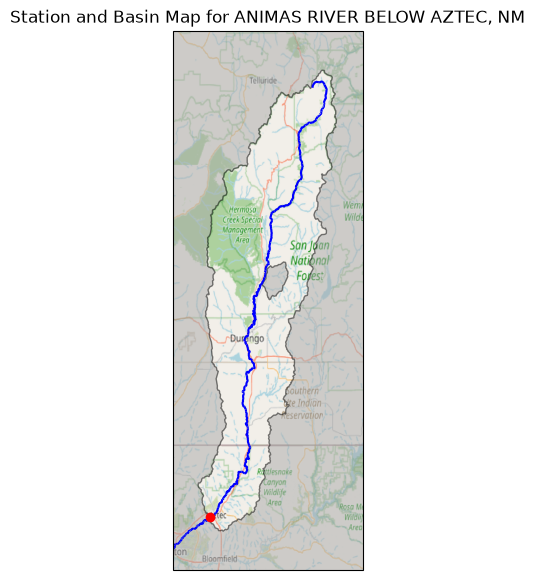

In [8]:
##############################################
#
# Make a map with Google Maps Cartopy API
#

add_Pretty_Map = True


# create an empty Hydro Network-Linked Data Index object

nldi = pynhd.NLDI()

# Extract the contributing basin geoDataFrame.
#  This is actually a MASK where the "fill" is on the outside!

basin     = nldi.get_basins(feature_ids = monitoring_location_id)

# Extract the upstream and downstream main flowlines
#  You can also get the smaller tributaries but for large
#  basins this will overwhelm the display.  You *may* be able
#  merge the Geodata

flw_main  = nldi.navigate_byid(fsource    = "nwissite",
                               fid        = monitoring_location_id,
                               navigation = "upstreamMain",
                               source     = "flowlines")
flw_down  = nldi.navigate_byid(fsource    = "nwissite",
                               fid        = monitoring_location_id,
                               navigation = "downstreamMain",
                               source     = "flowlines")

# Begin creating the figure object.

fig = plt.figure(figsize=(11, 7))

# create a simple localized platform (I like Transverse Mercator customized on my location)
#   It may send pink box of judgey-ment telling you that you need a real projection to get
#   a credible answer.  But given that you need a center of projection to get the projection
#   information, it's just now being...  well...   I've been told to be nice.

basin_centroids = basin["geometry"].centroid

centroid_lon    = basin_centroids.get_coordinates()["x"].values[0]
centroid_lat    = basin_centroids.get_coordinates()["y"].values[0]

myproj = ccrs.LambertAzimuthalEqualArea(central_latitude  = centroid_lat,
                                        central_longitude = centroid_lon)

min_lon = basin["geometry"].get_coordinates()["x"].min()
max_lon = basin["geometry"].get_coordinates()["x"].max()
min_lat = basin["geometry"].get_coordinates()["y"].min()
max_lat = basin["geometry"].get_coordinates()["y"].max()



# add a plot element just one field aka the "Axes"

ax = fig.add_subplot(1,  # nrows
                     1,  # ncols
                     1,  # index of figure you're installing
                     projection = myproj)  # cartopy CRS Projection

if add_Pretty_Map:

    # Request Map Tiles

    map_tiles = cimgt.OSM(desired_tile_form="RGB")
    print("Maptiles in")

    # Lay down the map tiles
    print("Maptiles out")

    ax.add_image(map_tiles, 9) # the second argument is the scale.
                               #  I advise starting with 9
                               #  Make the number smaller to zoom out,
                               #  and bigger to zoom in.

else:

    # just use classic vector lines

    ax.add_feature(feature    = cfeature.STATES,
                   edgecolor  = "grey",
                   facecolor  = 'none')
    ax.add_feature(feature    = cfeature.COASTLINE,
                   edgecolor  = "grey",
                   facecolor  = 'none')
    ax.add_feature(feature    = USCOUNTIES,
                   linewidths = 0.5,
                   edgecolor  = "grey",
                   facecolor  = 'none')

# Manually Setting Limits

ax.set_extent([min_lon-0.1, max_lon+0.1,
               min_lat-0.1, max_lat+0.1])

# Drop Polygon
#  And here's the fun.  Since it's a "mask" the "facecolor"
#    of the polygon itself is the mask, so while the basin
#    will be clear, the outside will be your facecolor and
#    the "edgecolor" can be the outline.

basin.plot(ax        = ax,
           facecolor = "darkgrey",
           edgecolor = "black",
           alpha     = 0.5,
           transform = ccrs.Geodetic())

# Drop Main Stem
#  There is no immediate way to "thin" the tributaries
#    inside the basin but you can plot the main stem
#    and below the main stem.


flw_main.plot(ax        = ax,
              color     = "blue",
              transform = ccrs.Geodetic())

flw_down.plot(ax        = ax,
              color     = "blue",
              transform = ccrs.Geodetic())

# Drop Station Point

df_metadata.plot(ax        =              ax,
                    color     =           "Red",
                    transform = ccrs.Geodetic(),
                    zorder    =             100)

# Good People Label their Plots

ax.set_title("Station and Basin Map for " + station_names_for_plots)

# Display and Close Graph

plt.show()

#
##############################################

OK, now back to work!

### 4.5 Now Let's Fetch the Actual Data (i.e., the Numbers)

The command here for us is to extract the daily aggregated data [dataretrieval.waterdata.get_daily()](https://doi-usgs.github.io/dataretrieval-python/reference/waterdata.html#dataretrieval.waterdata.get_daily)

Now one thing we have above using the example in the documentation above is that we already have one column identifying the specific time series identNow, one thing we have above using the example in the documentation above is that we already have one column identifying the specific time series identification code, which identifies the specific granular timeseries in the USGS database ID code, which identifies the specific granular timeseries in the USGS database.  NWIS had that too, but it was just called the 'time series.' or 'TS."

We will need to convert the column in the metadata dataframe into a traditional Python list.

Also, to better arrange the data, we can create a simple multi-index dataframe in pandas with [pandas.DataFrame.set_index()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.set_index.html)

Also notice how I am changing the names of certain columns.


<div class="alert alert-danger" role="alert">
<p><strong>***SEABORN PLOTTING WARNING***</strong> A warning for those of you who want to work with seaborn for time-series line plots.</p>
    
<p>While pandas and matplotlib can handle missing data when plotting, leaving gaps where time series are broken, seaborn.lineplot() wipes numpy.NaNs from the internal processing for plots.</p>
        
</div>



Retrieving: daily · 1 page · 8,691 rows · 997/1,000 requests remaining


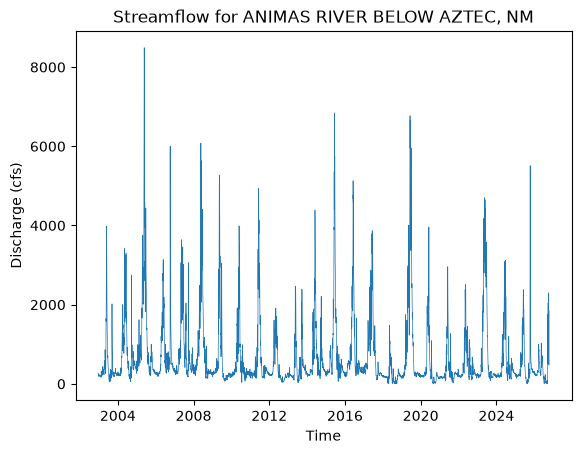

In [9]:
##############################################
#
# Extract Time Series Data (Single Station)
#

df_ts_data, md_ts_data =  \
    waterdata.get_daily(monitoring_location_id = monitoring_location_id,
                        parameter_code         = parameter_code,
                        statistic_id           = statistic_id)

# Get the Time Series for All Stations

df_ts_data.set_index(['time'], inplace=True)


#
# Drop Un-needed columns (or here, just keep the two I want)
#

df_ts_data = df_ts_data[ ["value",
                          "qualifier"] ]

#
# Change the columns names to people-friendly ones.
#

df_ts_data = df_ts_data.rename( columns = {"value":"Discharge",
                                       "qualifier":"Discharge_QC"})

itables.show(df = df_ts_data)

#
##############################################

##############################################
#
#  Plot Results
#

sns.lineplot(data      = df_ts_data,
             x         = "time",
             y         = "Discharge",
             linewidth = 0.5)

plt.title("Streamflow for "+ station_names_for_plots)
plt.xlabel("Time")
plt.ylabel("Discharge (cfs)")
plt.show()

#
##############################################

### 4.6 Filling Missing Records

It's not uncommon for some datasets to have missing data from a continuous series but archived *without* missing records.

Here since we have a multiindex system, we are first iterate through the stations with [pandas.DataFrame.groupby()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html).  

One inside of a group of stations with [pandas.DataFrame.resample()](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html)

Resample will require an aggregation method and here we are using just the "first" method to use the first value of the interval. And if the data is missing that first value is just a "NaN."

I will adding for the water years here.

In [10]:
##############################################
#
# Resample to daily increments with NaNs in the new empty records.
#

df_ts_data_resampled = df_ts_data.resample(rule  =   '1D',
                                           level = 'time'). \
                                  agg(func = 'first')

#
##############################################

And let's add a water year... (I'm also cutting off our WYs at 2025)

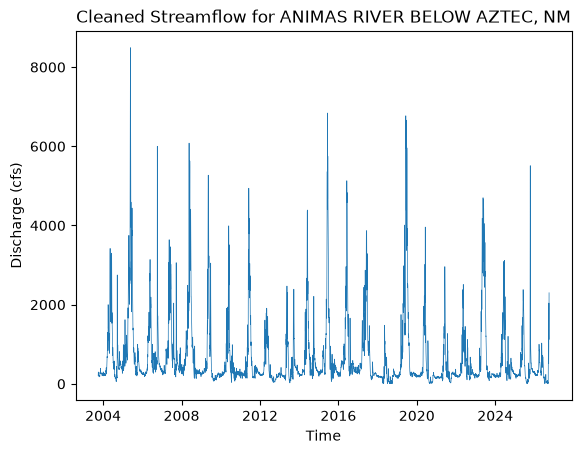

In [11]:
##############################################
#
# Adding a Water Year
#

df_ts_data_resampled['WaterYear'] = np.where(df_ts_data_resampled.index.get_level_values('time').month < 10,
                                             df_ts_data_resampled.index.get_level_values('time').year,
                                             df_ts_data_resampled.index.get_level_values('time').year + 1)

#
# Cutting Water Year
#

df_ts_data_resampled = df_ts_data_resampled[df_ts_data_resampled['WaterYear'] < df_ts_data_resampled['WaterYear'].max()]
df_ts_data_resampled = df_ts_data_resampled[df_ts_data_resampled['WaterYear'] > df_ts_data_resampled['WaterYear'].min()]

#
# Display
#

itables.show(df_ts_data_resampled)

#
##############################################

##############################################
#
#  Plot Results
#

sns.lineplot(data      = df_ts_data_resampled,
             x         = "time",
             y         = "Discharge",
             linewidth = 0.5)

plt.title("Cleaned Streamflow for "+ station_names_for_plots)
plt.xlabel("Time")
plt.ylabel("Discharge (cfs)")
plt.show()

#
##############################################

## 5. NOW PLAY! (Let's filter the Our station to make an Annual Max Series (AMS).

Here I am just getting the Annual Max Series (a.k.a., an "AMS" series) for all the observations.  I'm also using some diagnostics, such as determining the beginning and end of the water year.

I'm including a plot to graphically inspect the "inventory" of the various stations.  I can use this to better prune my empty water years or gaps in my data record.




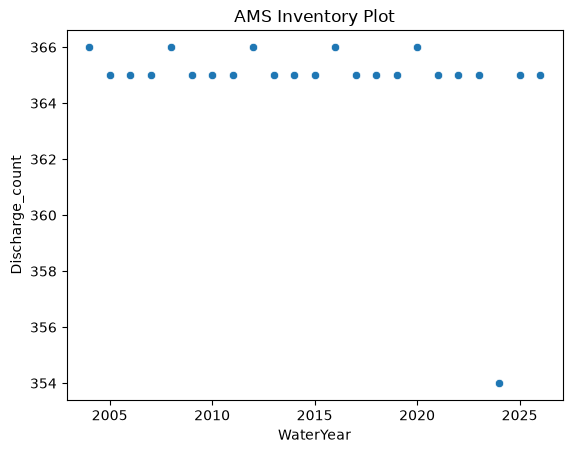

In [12]:
##############################################
#
# Annual Max Series Multi
#

df_ams_resampled = df_ts_data_resampled.reset_index(). \
                                        groupby(by = ["WaterYear"]). \
                                        agg(     {"time":{"min","max"},
                                             "Discharge":{"max","count"}})

df_ams_resampled = flatten_multi_col_index(df_ams_resampled)

#
# Identifying my max event dates
#


max_value_date = df_ts_data_resampled.reset_index().     \
                                      set_index("time").  \
                                      groupby(by = "WaterYear")['Discharge'].idxmax() #. \

max_value_date.name = "Max Discharge Date"

df_ams_resampled["Max Discharge Date"] = max_value_date


itables.show(df_ams_resampled)

#
# Adding diagnostic plot
#


g = sns.scatterplot(data =         df_ams_resampled,
                    x    =              "WaterYear",
                    y    =        "Discharge_count")


plt.title("AMS Inventory Plot")
plt.show()

#
##############################################

And let's close with a classic head-on-pike presentation method.

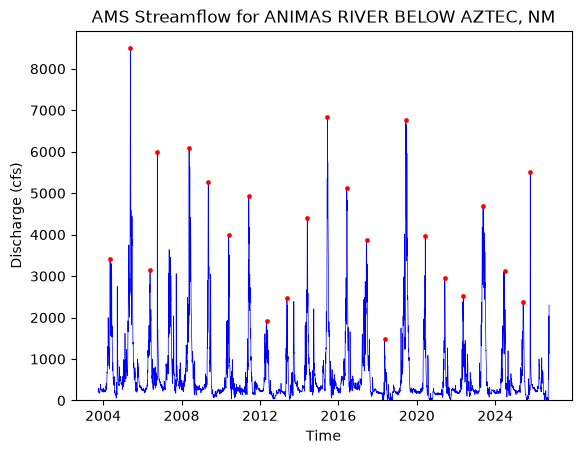

In [13]:
##############################################
#
# Annual Max Series Single
#

sns.lineplot(data      = df_ts_data_resampled,
             x         = "time",
             y         = "Discharge",
             color     = "blue",
             linewidth = 0.5)

# Heads on Pikes are fun.

sns.scatterplot(data       = df_ams_resampled,
                x          = "Max Discharge Date",
                y          = "Discharge_max",
                color      = "red",
                edgecolors = None, # a marker can have an outline color (default is often white)
                s          = 10,   # makersize (pointsize)
                zorder     = 99)   # bigger zorders bring it to the front


plt.title("AMS Streamflow for "+ station_names_for_plots)
plt.xlabel("Time")
plt.ylabel("Discharge (cfs)")
plt.ylim(bottom=0)
plt.show()


#
##############################################

## 6. Version Information

*Version Information* is a package developed by J.R. Johansson and operates as what the iPython/Jupyter Environments calls ["Magic Line" commands](https://jakevdp.github.io/PythonDataScienceHandbook/01.03-magic-commands.html) which are invoked by a "%."  This one is convenient since it displays detailed information on the versions of Python, Jupyter, and any other denoted packages (but for those, you DO need to delete them since this is running "outside" of your notebook program.

The output will be in JSON format in the Jupyter Lab Notebook, but it will be a professional-looking table when rendered as an HTML file.

In [14]:
################################################################
#
# Loading Version Information
#

%load_ext version_information
%version_information numpy, matplotlib, pandas, geopandas, dataretrieval, pynhd, cartopy, itables, version_information

#
################################################################

Software,Version
Python,3.13.15 64bit [Clang 19.1.7 ]
IPython,9.17.1
OS,macOS 27.0.1 arm64 arm 64bit Mach O
numpy,2.5.3
matplotlib,3.11.2
pandas,3.0.6
geopandas,1.2.0
dataretrieval,1.4.0
pynhd,0.20.0
cartopy,0.26.0
